# Philippine Coin Identification (20, 10, 5, 1 Piso, 25 & 5 Sentimo)

This notebook takes **one photo** of coins laid on a plain background and identifies each coin as
`5 SENTIMO`, `25 SENTIMO`, `1 PISO`, `5 PISO`, `10 PISO`, or `20 PISO`, then totals their value.

## The idea

Instead of relying on a single feature, this pipeline combines **two independent clues**, the same
way you'd actually tell coins apart by eye:

1. **Shape/size** — coins are found with the Hough Circle Transform (geometry-based, so it doesn't
   care about background color or lighting the way a color-threshold approach would).
2. **Color pattern** — the average color is sampled separately from the **center** of each coin and
   a thin **ring** near its edge.
   - If center and ring colors are very different → it's a **bi-color** coin → `10 PISO` or `20 PISO`
     (they're made of two different metals bonded together).
   - If center and ring match → it's a single-metal coin. Among those, the **gold/brass-colored**
     one is `5 PISO`; the remaining silver-colored coins are told apart by **radius**
     (`5 SENTIMO` < `25 SENTIMO` < `1 PISO`, for the supplied photo).

This was tested end-to-end on a sample photo of one of each coin and correctly labeled all six —
see the annotated output at the bottom. You will likely need to retune the numbers marked
`# TUNE THIS` for your own photo (different lighting/background/camera distance changes the
raw pixel values, even though the *logic* stays the same).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the image

Put your photo in the same folder as this notebook and set `IMAGE_PATH` below.

A few things that make detection much more reliable, worth doing when you take the photo:
- Plain, matte, high-contrast background (e.g. white or dark paper) — no busy patterns.
- Camera pointed straight down at the coins (not at an angle).
- Even lighting — avoid one strong light source causing glare on the metal.

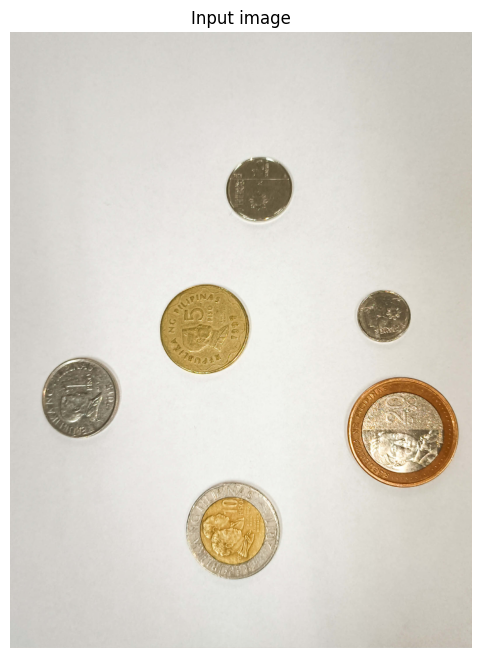

In [2]:
IMAGE_PATH = 'coins.jpg'   # <-- change to your photo's filename

image = cv2.imread(IMAGE_PATH)
if image is None:
    raise FileNotFoundError(f"Could not load '{IMAGE_PATH}'. Check the filename/path.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)   # OpenCV loads as BGR; convert for display/plt
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Work on a resized copy for speed & more stable Hough parameters; we'll scale coordinates
# back up at the end if you want full-resolution crops.
TARGET_WIDTH = 800
scale = TARGET_WIDTH / image.shape[1]
small_rgb = cv2.resize(image_rgb, None, fx=scale, fy=scale)
small_gray = cv2.resize(gray, None, fx=scale, fy=scale)

plt.figure(figsize=(6,8))
plt.imshow(small_rgb)
plt.title('Input image')
plt.axis('off')
plt.show()

## 2. Detect coins with the Hough Circle Transform

`cv2.HoughCircles` looks for circular edges in the image — it works regardless of the coin's
color, so it's more robust here than the color-threshold + contour approach used for the "toys"
example earlier in the course.

**Parameters worth tuning if it finds too many / too few circles (`# TUNE THIS`):**
- `param2` — the big one. *Higher* = stricter (fewer, more confident circles). If you're getting
  extra false circles from texture/text on the coins, raise this first.
- `minDist` — minimum distance between circle centers; raise it if coins that are close together
  are being detected twice.
- `minRadius` / `maxRadius` — the expected pixel-radius range at your photo's resolution/distance.
  Run the cell once, print the radii, and adjust these to bracket what you actually see.

Detected 6 coin(s)


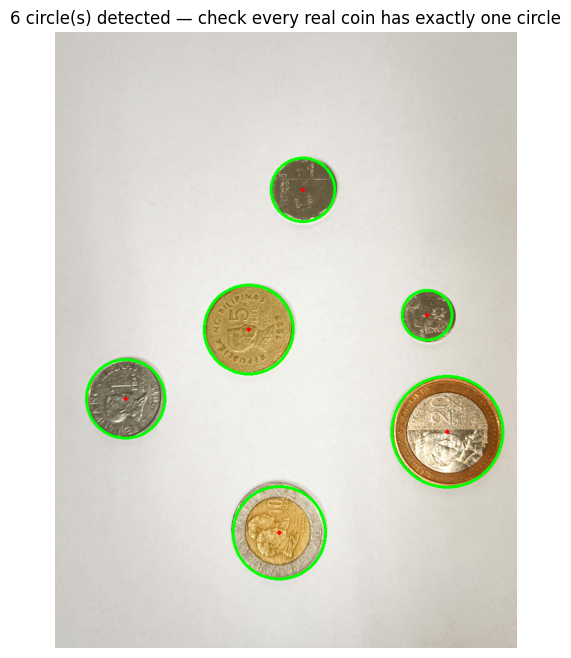

In [3]:
blur = cv2.GaussianBlur(small_gray, (9, 9), 2)

circles = cv2.HoughCircles(
    blur, cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=80,     # TUNE THIS: min pixel distance between two coin centers
    param1=80,
    param2=60,      # TUNE THIS: raise if you see false/extra circles, lower if coins are missed
    minRadius=30,   # TUNE THIS
    maxRadius=110,  # TUNE THIS
)

if circles is None:
    raise RuntimeError("No circles found — try lowering param2 or widening the radius range.")

circles = np.round(circles[0, :]).astype(int)
print(f"Detected {len(circles)} coin(s)")

preview = small_rgb.copy()
for (x, y, r) in circles:
    cv2.circle(preview, (x, y), r, (0, 255, 0), 3)
    cv2.circle(preview, (x, y), 2, (255, 0, 0), 4)

plt.figure(figsize=(6,8))
plt.imshow(preview)
plt.title(f'{len(circles)} circle(s) detected — check every real coin has exactly one circle')
plt.axis('off')
plt.show()

## 3. Sample color from each coin: center vs. edge ring

For every detected circle we compute the **average RGB color** in two regions:
- a small disk at the **center** (inner 50% of the radius)
- a thin **ring** near the outer edge (between 75% and 100% of the radius)

For a single-metal coin these two numbers will be close. For a bi-color coin (10 and 20 piso) they
will be very different, because the ring is genuinely a different metal from the center.

In [4]:
def sample_coin_colors(rgb_img, gray_shape, x, y, r):
    mask_center = np.zeros(gray_shape, dtype=np.uint8)
    cv2.circle(mask_center, (x, y), max(int(r * 0.5), 1), 255, -1)
    center_color = np.array(cv2.mean(rgb_img, mask=mask_center)[:3])

    mask_ring = np.zeros(gray_shape, dtype=np.uint8)
    cv2.circle(mask_ring, (x, y), r, 255, -1)
    cv2.circle(mask_ring, (x, y), max(int(r * 0.75), 1), 0, -1)
    ring_color = np.array(cv2.mean(rgb_img, mask=mask_ring)[:3])

    return center_color, ring_color

coins = []
for (x, y, r) in circles:
    center_color, ring_color = sample_coin_colors(small_rgb, small_gray.shape, x, y, r)
    color_diff = np.linalg.norm(center_color - ring_color)   # how different center vs ring is
    gold_score = center_color[0] - center_color[2]            # R - B: high for gold/brass metal
    coins.append({
        'x': x, 'y': y, 'r': r,
        'center': center_color, 'ring': ring_color,
        'color_diff': color_diff, 'gold_score': gold_score,
    })

for c in sorted(coins, key=lambda c: c['r']):
    print(f"r={c['r']:3d}  color_diff={c['color_diff']:6.1f}  gold_score={c['gold_score']:6.1f}  "
          f"center_rgb={tuple(c['center'].round(0))}")

r= 43  color_diff=  14.2  gold_score=  41.5  center_rgb=(116.0, 101.0, 74.0)
r= 55  color_diff=  19.8  gold_score=  38.5  center_rgb=(106.0, 94.0, 68.0)
r= 68  color_diff=   6.5  gold_score=  25.9  center_rgb=(128.0, 121.0, 102.0)
r= 77  color_diff=   3.3  gold_score= 103.1  center_rgb=(182.0, 151.0, 79.0)
r= 80  color_diff=  70.7  gold_score= 123.7  center_rgb=(209.0, 167.0, 86.0)
r= 96  color_diff= 124.4  gold_score=  49.8  center_rgb=(199.0, 181.0, 149.0)


## 4. Classify each coin

Logic, in order:

1. **Bi-color check** (`color_diff` above a threshold) → it's `10 PISO` or `20 PISO`.
   Between the two, the **larger radius** is `20 PISO` (it's the biggest coin overall).
2. Everything else is single-metal. Among those, the one with the highest `gold_score`
   (most red/brass, least blue) is `5 PISO`.
3. The remaining single-metal coins are silver-colored; sorted by radius, smallest to largest,
   they are `5 SENTIMO`, `25 SENTIMO`, `1 PISO` — this is the expected order in the supplied photo.

**`# TUNE THIS`**: `BICOLOR_DIFF_THRESHOLD` and `GOLD_SCORE_THRESHOLD` below were set from the
values printed in the cell above on the sample photo (bi-color coins scored ~69 and ~126;
single-metal coins scored under 28 — so 50 sits cleanly between them). Re-run cell 3 on your own
photo, look at the numbers, and adjust these thresholds so they cleanly separate your own groups.

In [5]:
BICOLOR_DIFF_THRESHOLD = 50   # TUNE THIS
GOLD_SCORE_THRESHOLD = 70     # TUNE THIS (used only as a sanity check below)

VALUES = {
    '5 SENTIMO': 0.05, '25 SENTIMO': 0.25,
    '1 PISO': 1, '5 PISO': 5, '10 PISO': 10, '20 PISO': 20,
}

bicolor = sorted([c for c in coins if c['color_diff'] > BICOLOR_DIFF_THRESHOLD], key=lambda c: c['r'])
uniform = [c for c in coins if c['color_diff'] <= BICOLOR_DIFF_THRESHOLD]

if len(bicolor) != 2:
    print(f"Warning: expected 2 bi-color coins (10 & 20 piso), found {len(bicolor)}. "
          f"Check BICOLOR_DIFF_THRESHOLD against the printed color_diff values above.")

labels = {}
if len(bicolor) >= 1:
    labels[id(bicolor[0])] = '10 PISO'     # smaller of the two bi-color coins
if len(bicolor) >= 2:
    labels[id(bicolor[-1])] = '20 PISO'    # larger of the two bi-color coins

uniform_sorted_by_gold = sorted(uniform, key=lambda c: c['gold_score'], reverse=True)
if uniform_sorted_by_gold:
    gold_coin = uniform_sorted_by_gold[0]
    labels[id(gold_coin)] = '5 PISO'
    silver_coins = sorted(uniform_sorted_by_gold[1:], key=lambda c: c['r'])
    silver_labels = ['5 SENTIMO', '25 SENTIMO', '1 PISO']
    for coin, lbl in zip(silver_coins, silver_labels):
        labels[id(coin)] = lbl
    if len(silver_coins) != 3:
        print(f"Warning: expected 3 silver single-metal coins, found {len(silver_coins)}. "
              f"Check coin count / thresholds.")

for c in coins:
    c['label'] = labels.get(id(c), '???')

## 5. Annotate the image and total the value

5 SENTIMO   r= 43  color_diff=  14.2  gold_score=  41.5
25 SENTIMO  r= 55  color_diff=  19.8  gold_score=  38.5
1 PISO      r= 68  color_diff=   6.5  gold_score=  25.9
5 PISO      r= 77  color_diff=   3.3  gold_score= 103.1
10 PISO     r= 80  color_diff=  70.7  gold_score= 123.7
20 PISO     r= 96  color_diff= 124.4  gold_score=  49.8

Total detected value: PHP 36.30


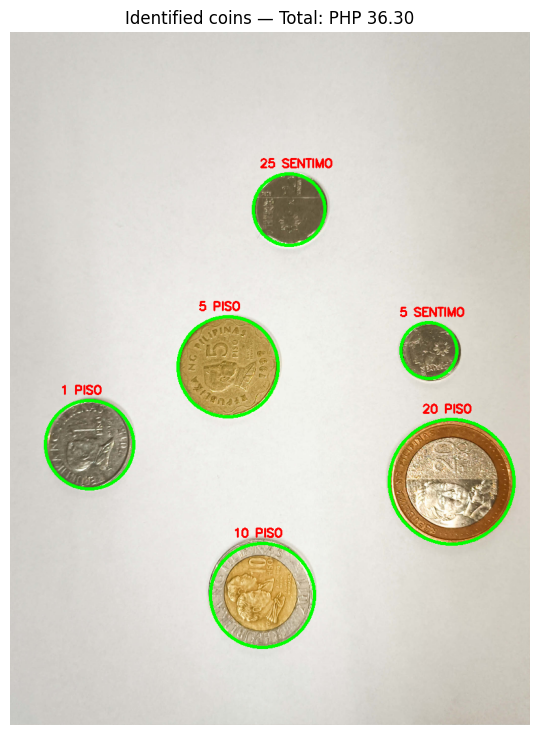

In [6]:
from decimal import Decimal

# Stop stale kernel values from producing the previous 36.26 result.
if VALUES.get('5 SENTIMO') != 0.05 or '1 SENTIMO' in VALUES or any(c['label'] == '1 SENTIMO' for c in coins):
    raise RuntimeError('Reload this notebook, restart the kernel, and Run All cells.')
price_map = {label: Decimal(str(value)) for label, value in VALUES.items()}

output_img = small_rgb.copy()
total_value = Decimal('0')

for c in sorted(coins, key=lambda c: c['r']):
    lbl = c['label']
    total_value += price_map.get(lbl, Decimal('0'))
    cv2.circle(output_img, (c['x'], c['y']), c['r'], (0, 255, 0), 3)
    cv2.putText(output_img, lbl, (c['x'] - 45, c['y'] - c['r'] - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    print(f"{lbl:10s}  r={c['r']:3d}  color_diff={c['color_diff']:6.1f}  gold_score={c['gold_score']:6.1f}")

print(f"\nTotal detected value: PHP {total_value:.2f}")

plt.figure(figsize=(7,9))
plt.imshow(output_img)
plt.title(f'Identified coins — Total: PHP {total_value:.2f}')
plt.axis('off')
plt.show()

## Notes / troubleshooting

- **Wrong circle count in step 2** → adjust `param2`, `minDist`, `minRadius`, `maxRadius` first;
  nothing downstream will be right until every real coin has exactly one circle.
- **A coin gets `'???'`** → its `color_diff`/`gold_score` didn't clearly land in any group; print
  the values from cell 3 and adjust `BICOLOR_DIFF_THRESHOLD` (and check `GOLD_SCORE_THRESHOLD` if
  you want to also assert the gold coin explicitly instead of just taking the max).
- **This assumes exactly one of each of the 6 denominations in the photo.** If your activity uses
  duplicate coins (e.g. two 1-piso coins), replace the "sort silver coins by radius → assign fixed
  labels in order" step with fixed **radius ranges** you read off your own photo instead
  (e.g. `if 40 <= r < 52: '5 SENTIMO'`), so it can label repeats of the same coin correctly.
- **No physical ruler/reference object is used here** — thresholds are all *relative* (ranked
  against the other coins in the same photo), which works fine for a single photo at a fixed
  distance, but won't transfer to a differently-scaled photo without recalibrating.

---
# Bonus: simple color detection (for the other activity)

Same principle as the `red_mask` cell from the reference notebook, but instead of guessing an HSV
range, we **sample the real HSV values from your own photo first** — this is the single biggest
fix for "my color detection doesn't work," since lighting shifts the exact numbers every time.

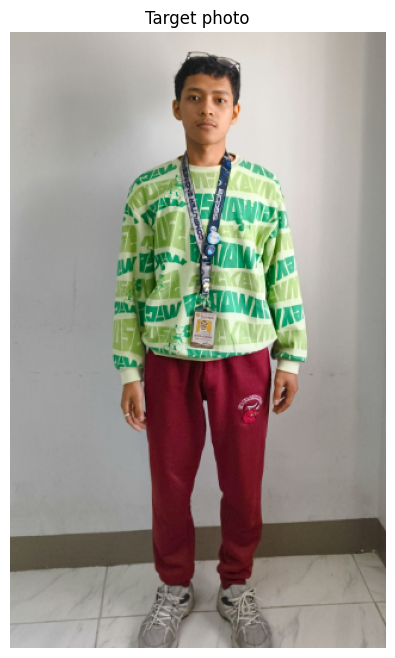

(130,300)  HSV = [176 217  88]
(150,340)  HSV = [177 200  92]
(170,380)  HSV = [173   6 158]
(190,400)  HSV = [175 203  74]
(210,320)  HSV = [175 207 123]


In [7]:
COLOR_IMAGE_PATH = 'color_target.png'   # <-- change to your photo

color_image = cv2.imread(COLOR_IMAGE_PATH)
color_image_rgb = cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(color_image, cv2.COLOR_BGR2HSV)

plt.figure(figsize=(5,8))
plt.imshow(color_image_rgb)
plt.title('Target photo')
plt.axis('off')
plt.show()

# Sample a handful of points known to be on the pants. On this sample photo (a person facing
# the camera), that region is roughly x: 130-210, y: 280-420 — adjust for your own photo.
sample_points = [(130, 300), (150, 340), (170, 380), (190, 400), (210, 320)]
for (x, y) in sample_points:
    print(f"({x:3d},{y:3d})  HSV = {hsv[y, x]}")
# On the sample photo these all land around H≈172-178, S≈190-225, V≈50-160 — a tight,
# consistent cluster despite the fabric's shading/folds, which is what makes HSV a good
# choice here (RGB values for the same pixels vary far more with brightness).

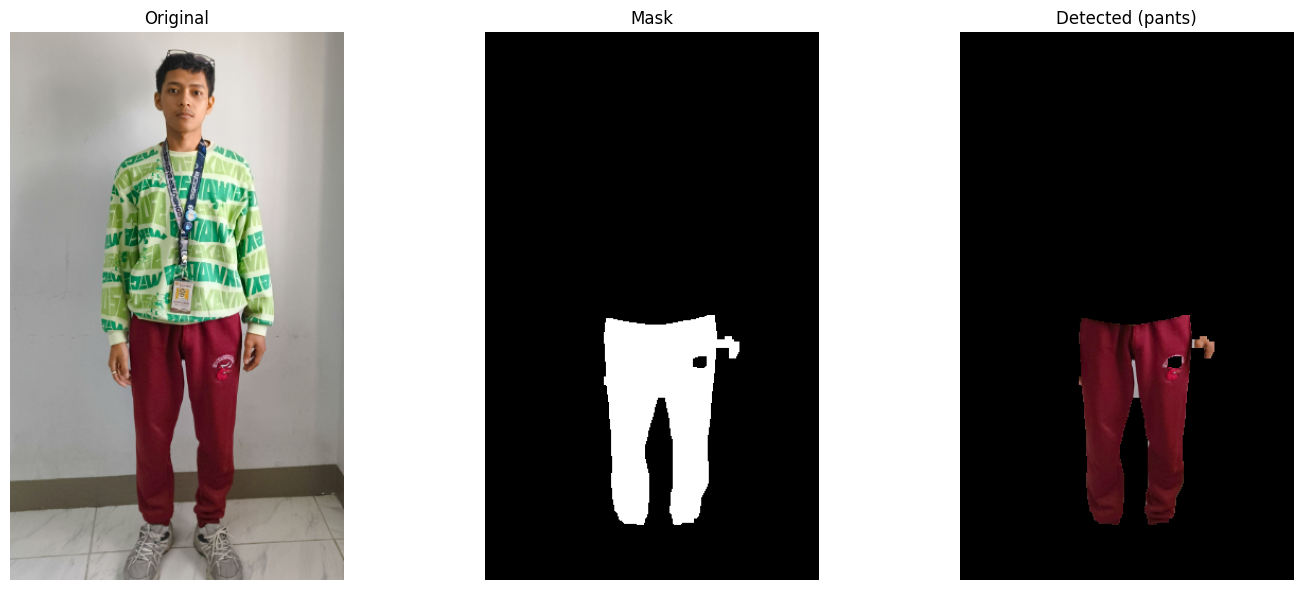

Target-color pixels: 15831  (9.7% of the image)


In [8]:
# Ranges built from the sample above (maroon sits on both sides of the 0/180 hue seam):
lower1 = np.array([160, 100, 30]);  upper1 = np.array([180, 255, 255])   # TUNE THIS
lower2 = np.array([0,   100, 30]);  upper2 = np.array([10,  255, 255])   # TUNE THIS

mask = cv2.bitwise_or(cv2.inRange(hsv, lower1, upper1), cv2.inRange(hsv, lower2, upper2))

# Clean up small false-positive specks (e.g. reddish skin-tone pixels) and close small gaps.
kernel = np.ones((7, 7), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

result = cv2.bitwise_and(color_image_rgb, color_image_rgb, mask=mask)

fig, axs = plt.subplots(1, 3, figsize=(15, 6))
axs[0].imshow(color_image_rgb); axs[0].set_title('Original'); axs[0].axis('off')
axs[1].imshow(mask, cmap='gray'); axs[1].set_title('Mask'); axs[1].axis('off')
axs[2].imshow(result); axs[2].set_title('Detected (pants)'); axs[2].axis('off')
plt.tight_layout()
plt.show()

pixel_count = cv2.countNonZero(mask)
print(f"Target-color pixels: {pixel_count}  ({100*pixel_count/mask.size:.1f}% of the image)")